# 01. EDA: PTB-XL, 5 диагностических суперклассов

Разведочный анализ на основе `src/data.py`. Данные берутся из кэша (`load_splits`), сигналы — **сырые, в мВ** (без нормализации).

**Правило разбиения (правила проекта):** анализ делается только по **train (фолды 1–8) + val (фолд 9)**. Тестовый фолд 10 здесь не загружается вообще: решения по данным не должны опираться на него.

Не медицинское изделие, исследовательский прототип.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_config, load_splits, load_metadata

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
SEED = 42
rng = np.random.default_rng(SEED)

cfg_all = load_config(ROOT / "configs" / "data.yaml")
cfg = cfg_all["data"]
CLASSES = cfg["classes"]
# test сознательно не загружаем
data, meta = load_splits(cfg, splits=("train", "val"), normalize=False)
LEADS = meta["leads"]

X = np.concatenate([data["train"].X, data["val"].X])
y = np.concatenate([data["train"].y, data["val"].y])
ecg_id = np.concatenate([data["train"].ecg_id, data["val"].ecg_id])
split = np.array(["train"] * len(data["train"].y) + ["val"] * len(data["val"].y))
print(f"Записей (train+val): {len(y)}, сигнал: {X.shape[1:]} (отведения x отсчёты), отведения: {LEADS}")
print("Исключено без суперкласса (train/val):",
      {s: meta["stats"]["splits"][s]["excluded_no_superclass"] for s in ("train", "val")})

Записей (train+val): 19230, сигнал: (12, 1000) (отведения x отсчёты), отведения: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Исключено без суперкласса (train/val): {'train': 334, 'val': 37}


## 1. Распределение классов

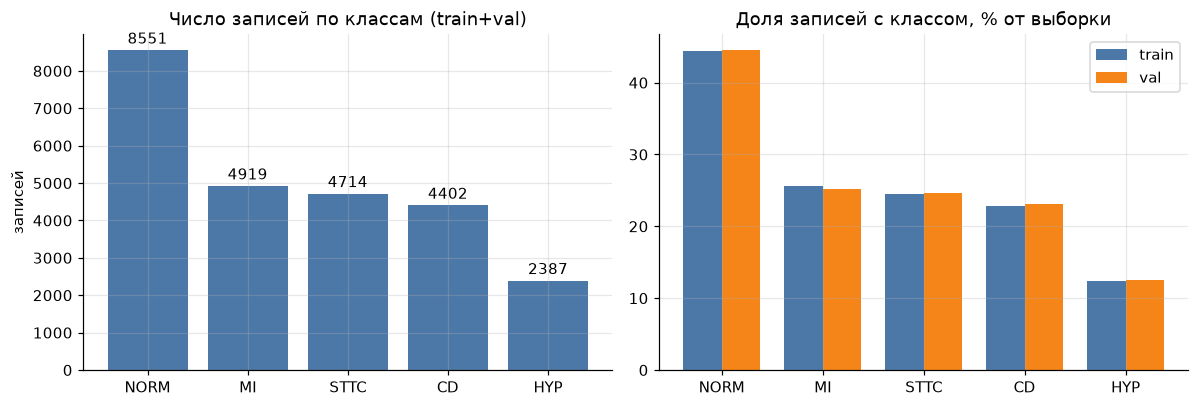

      train  val  total  train_%  val_%
NORM   7596  955   8551     44.5   44.5
MI     4379  540   4919     25.6   25.2
STTC   4186  528   4714     24.5   24.6
CD     3907  495   4402     22.9   23.1
HYP    2119  268   2387     12.4   12.5


In [2]:
counts = pd.DataFrame({s: y[split == s].sum(axis=0) for s in ("train", "val")}, index=CLASSES)
counts["total"] = counts.sum(axis=1)
share = counts.div([ (split == "train").sum(), (split == "val").sum(), len(y)], axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bars = axes[0].bar(CLASSES, counts["total"], color="#4C78A8")
axes[0].bar_label(bars, padding=2)
axes[0].set_title("Число записей по классам (train+val)")
axes[0].set_ylabel("записей")
w = 0.38
xs = np.arange(len(CLASSES))
axes[1].bar(xs - w / 2, share["train"], w, label="train", color="#4C78A8")
axes[1].bar(xs + w / 2, share["val"], w, label="val", color="#F58518")
axes[1].set_xticks(xs, CLASSES)
axes[1].set_title("Доля записей с классом, % от выборки")
axes[1].legend()
plt.tight_layout(); plt.show()
print(counts.assign(**{"train_%": share["train"].round(1), "val_%": share["val"].round(1)}).to_string())

**Вывод.** Классы несбалансированы умеренно: NORM — 8551 запись (44.5% и в train, и в val), MI — 4919 (25%), STTC — 4714 (24.6%), CD — 4402 (23%), HYP — 2387 (12.5%). Доли в train и val практически совпадают (расхождение ≤0.4 п.п.), то есть стратифицированные фолды PTB-XL работают как задумано и val пригоден для подбора порогов. Самый редкий класс — HYP (~1 к 8), по нему ждём самый шумный AUROC/F1. Для обучения разумно взвешивать BCE через pos_weight по train; общая сумма долей >100%, потому что задача multi-label. Без суперкласса исключено 334 записи в train и 37 в val.

## 2. Сочетания диагнозов

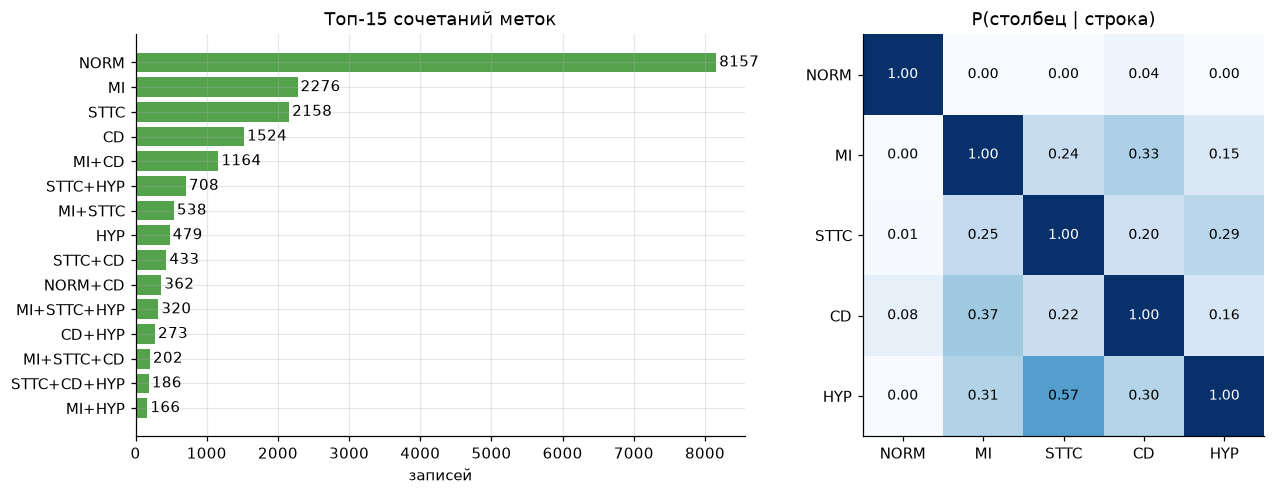

Меток на запись: {1: 14594, 2: 3670, 3: 825, 4: 141}
Записей с >1 меткой: 4636 (24.1%)


In [3]:
n_lab = y.sum(axis=1)
combo = pd.Series(["+".join(c for c, v in zip(CLASSES, row) if v) for row in y]).value_counts()
top = combo.head(15)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
bars = axes[0].barh(top.index, top.values, color="#54A24B")
axes[0].bar_label(bars, padding=2)
axes[0].set_title("Топ-15 сочетаний меток")
axes[0].set_xlabel("записей")

# P(столбец | строка): если у записи есть класс-строка, как часто есть класс-столбец
co = y.T.astype(float) @ y.astype(float)
cond = co / np.diag(co)[:, None]
im = axes[1].imshow(cond, vmin=0, vmax=1, cmap="Blues")
axes[1].set_xticks(range(len(CLASSES)), CLASSES); axes[1].set_yticks(range(len(CLASSES)), CLASSES)
axes[1].grid(False)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        axes[1].text(j, i, f"{cond[i, j]:.2f}", ha="center", va="center",
                     color="white" if cond[i, j] > 0.6 else "black", fontsize=9)
axes[1].set_title("P(столбец | строка)")
plt.tight_layout(); plt.show()

per_k = pd.Series(n_lab).value_counts().sort_index()
print("Меток на запись:", {int(k): int(v) for k, v in per_k.items()})
print(f"Записей с >1 меткой: {(n_lab > 1).sum()} ({100 * (n_lab > 1).mean():.1f}%)")

**Вывод.** Задача действительно multi-label: 24.1% записей (4636 из 19230) имеют 2–4 метки (1 метка — 14594, 2 — 3670, 3 — 825, 4 — 141). Самые частые одиночные комбинации — NORM (8157), MI (2276), STTC (2158), CD (1524); из составных лидируют MI+CD (1164), STTC+HYP (708) и MI+STTC (538). По матрице условных вероятностей: NORM практически не сочетается с другими классами (с MI/STTC/HYP ≈0–1%), при этом у 4% NORM-записей есть и CD — это стоит помнить как возможный шум меток. Среди записей с HYP 57% также имеют STTC, 31% — MI, 30% — CD; у MI в 37% случаев есть CD (в обратную сторону — 33%). Следствие: классы нельзя считать независимыми, softmax не подходит, нужен sigmoid на каждый класс; метрики стоит смотреть по классам, а не только macro.

## 3. Возраст и пол

Записей с возрастом >=120 (в PTB-XL так закодированы пациенты старше 89 лет): 253
Пропусков возраста: 253


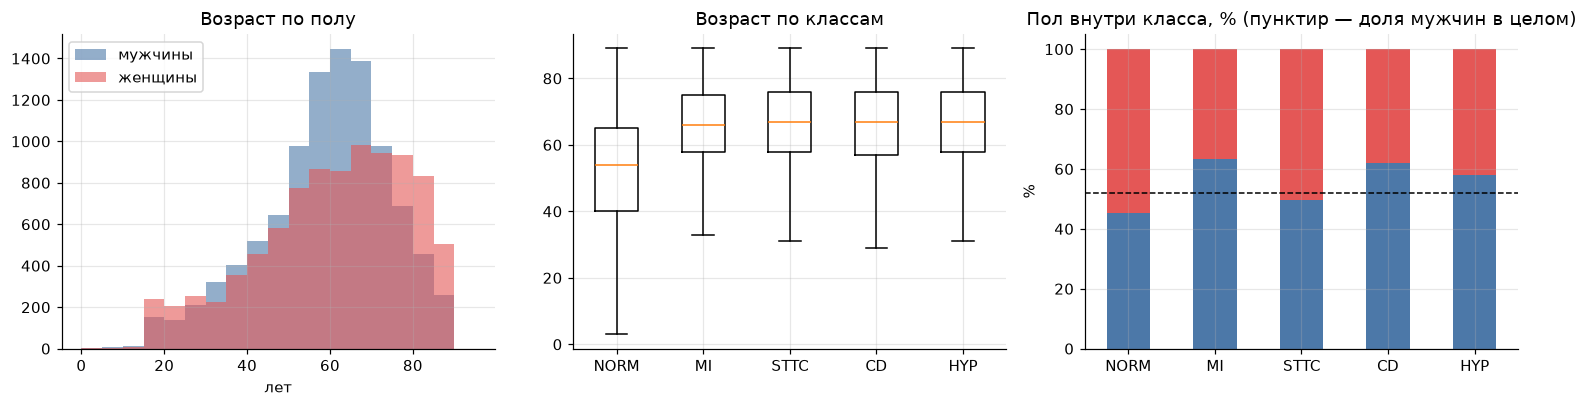

{'мужчины': 10001, 'женщины': 9229}
         mean   50%   std
sex                      
женщины  60.1  63.0  18.0
мужчины  58.5  60.0  15.4
Медиана возраста по классам: {'NORM': 54.0, 'MI': 66.0, 'STTC': 67.0, 'CD': 67.0, 'HYP': 67.0}
Доля женщин по классам, %: {'NORM': 54.7, 'MI': 36.8, 'STTC': 50.4, 'CD': 37.9, 'HYP': 42.0}


In [4]:
db, _ = load_metadata(ROOT / cfg["root"])
meta_df = db.loc[ecg_id, ["age", "sex", "patient_id"]].copy()
n_age300 = int((meta_df["age"] >= 120).sum())
print(f"Записей с возрастом >=120 (в PTB-XL так закодированы пациенты старше 89 лет): {n_age300}")
meta_df.loc[meta_df["age"] >= 120, "age"] = np.nan   # не подменяем значением: исключаем из статистики возраста
meta_df["sex"] = meta_df["sex"].map({0: "мужчины", 1: "женщины"})
print("Пропусков возраста:", int(meta_df["age"].isna().sum()))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for s, col in zip(["мужчины", "женщины"], ["#4C78A8", "#E45756"]):
    axes[0].hist(meta_df.loc[meta_df.sex == s, "age"].dropna(), bins=np.arange(0, 100, 5), alpha=0.6, label=s, color=col)
axes[0].set_title("Возраст по полу"); axes[0].set_xlabel("лет"); axes[0].legend()

ages_by_class = [meta_df["age"].to_numpy()[y[:, i] == 1] for i in range(len(CLASSES))]
ages_by_class = [a[~np.isnan(a)] for a in ages_by_class]
axes[1].boxplot(ages_by_class, tick_labels=CLASSES, showfliers=False)
axes[1].set_title("Возраст по классам")

sex_share = pd.DataFrame({c: meta_df.loc[y[:, i] == 1, "sex"].value_counts(normalize=True) * 100
                          for i, c in enumerate(CLASSES)}).T
sex_share = sex_share[["мужчины", "женщины"]]
sex_share.plot.bar(stacked=True, ax=axes[2], color=["#4C78A8", "#E45756"], rot=0, legend=False)
axes[2].axhline(meta_df["sex"].value_counts(normalize=True).mul(100)["мужчины"], color="k", ls="--", lw=1)
axes[2].set_title("Пол внутри класса, % (пунктир — доля мужчин в целом)")
axes[2].set_ylabel("%")
plt.tight_layout(); plt.show()

print(meta_df["sex"].value_counts().to_dict())
print(meta_df.groupby("sex")["age"].describe()[["mean", "50%", "std"]].round(1).to_string())
print("Медиана возраста по классам:", {c: float(np.median(a)) for c, a in zip(CLASSES, ages_by_class)})
print("Доля женщин по классам, %:", sex_share["женщины"].round(1).to_dict())

**Вывод.** Данные включают 10001 мужчин и 9229 женщин (≈52/48). У 253 записей возраст ≥120 — это не реальный возраст, а кодировка PTB-XL для пациентов старше 89 лет; в графиках они исключены из возраста (NaN), а не подменены значением. Средний возраст женщин 60.1 (медиана 63, σ=18.0), мужчин 58.5 (медиана 60, σ=15.4). Главный вывод — возраст сильно связан с классом: медиана для NORM 54 года против 66–67 лет для MI/STTC/CD/HYP. Пол тоже перекошен: женщин 54.7% среди NORM и 50.4% среди STTC, но лишь 36.8% среди MI и 37.9% среди CD (HYP — 42.0%). Значит, модель может частично опираться на косвенные признаки возраста/пола (например, на уровень шума и амплитуду) вместо патологии; полезно проверить качество в подгруппах по полу и возрасту на val и честно отметить это в отчёте.

## 4. Примеры ЭКГ каждого класса (12 отведений)

Для каждого класса берётся случайная запись (seed=42), у которой **только эта одна метка** — чтобы картинка не смешивала паттерны. Сигнал 100 Гц, 10 с, сырой, в мВ.

In [5]:
LAYOUT = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]
assert set(LAYOUT) == set(LEADS), LEADS
FS = cfg["sampling_rate"]

def plot_ecg(idx: int, title: str) -> None:
    """12 отведений в сетке 6x2 (левые — конечностные, правые — грудные)."""
    sig = X[idx]
    t = np.arange(sig.shape[1]) / FS
    fig, axes = plt.subplots(6, 2, figsize=(13, 9), sharex=True)
    for k, lead in enumerate(LAYOUT):
        ax = axes[k % 6, k // 6]
        ax.plot(t, sig[LEADS.index(lead)], lw=0.8, color="#222")
        ax.set_ylabel(lead, rotation=0, labelpad=14, va="center")
        ax.grid(True, alpha=0.4)
    axes[-1, 0].set_xlabel("с"); axes[-1, 1].set_xlabel("с")
    fig.suptitle(title, y=0.995)
    plt.tight_layout(); plt.show()

examples = {}
for i, c in enumerate(CLASSES):
    pure = np.flatnonzero((y[:, i] == 1) & (n_lab == 1))
    examples[c] = int(rng.choice(pure))
print({c: int(ecg_id[j]) for c, j in examples.items()}, "(ecg_id)")

{'NORM': 1891, 'MI': 20055, 'STTC': 16196, 'CD': 11288, 'HYP': 10602} (ecg_id)


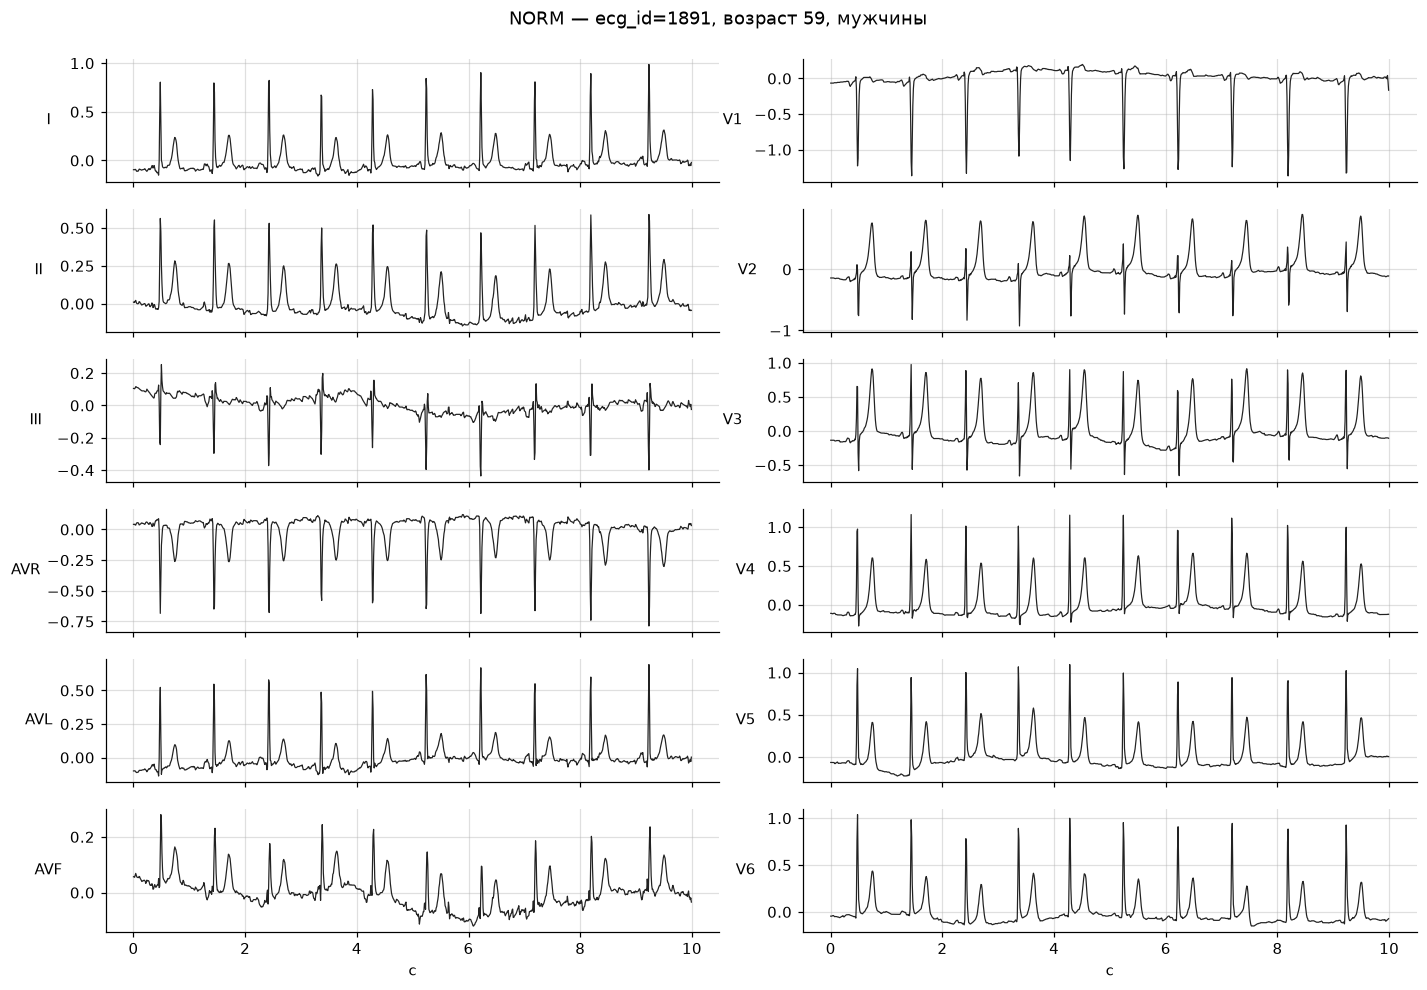

In [6]:
plot_ecg(examples["NORM"], f"NORM — ecg_id={ecg_id[examples['NORM']]}, "
         f"возраст {meta_df['age'].iloc[examples['NORM']]:.0f}, {meta_df['sex'].iloc[examples['NORM']]}")

**Вывод.** Ритм регулярный (RR ≈1 с, около 60 уд/мин), узкие комплексы QRS, положительный зубец T в I, II и V2–V6, отрицательный QRS в aVR — это типичный вид нормы. Заметен дрейф изолинии в III и aVF, то есть даже у «чистой» нормы сигнал не идеален. Это один случайный пример, а не доказательство различимости классов, и я не врач: описываю только то, что видно на графике.

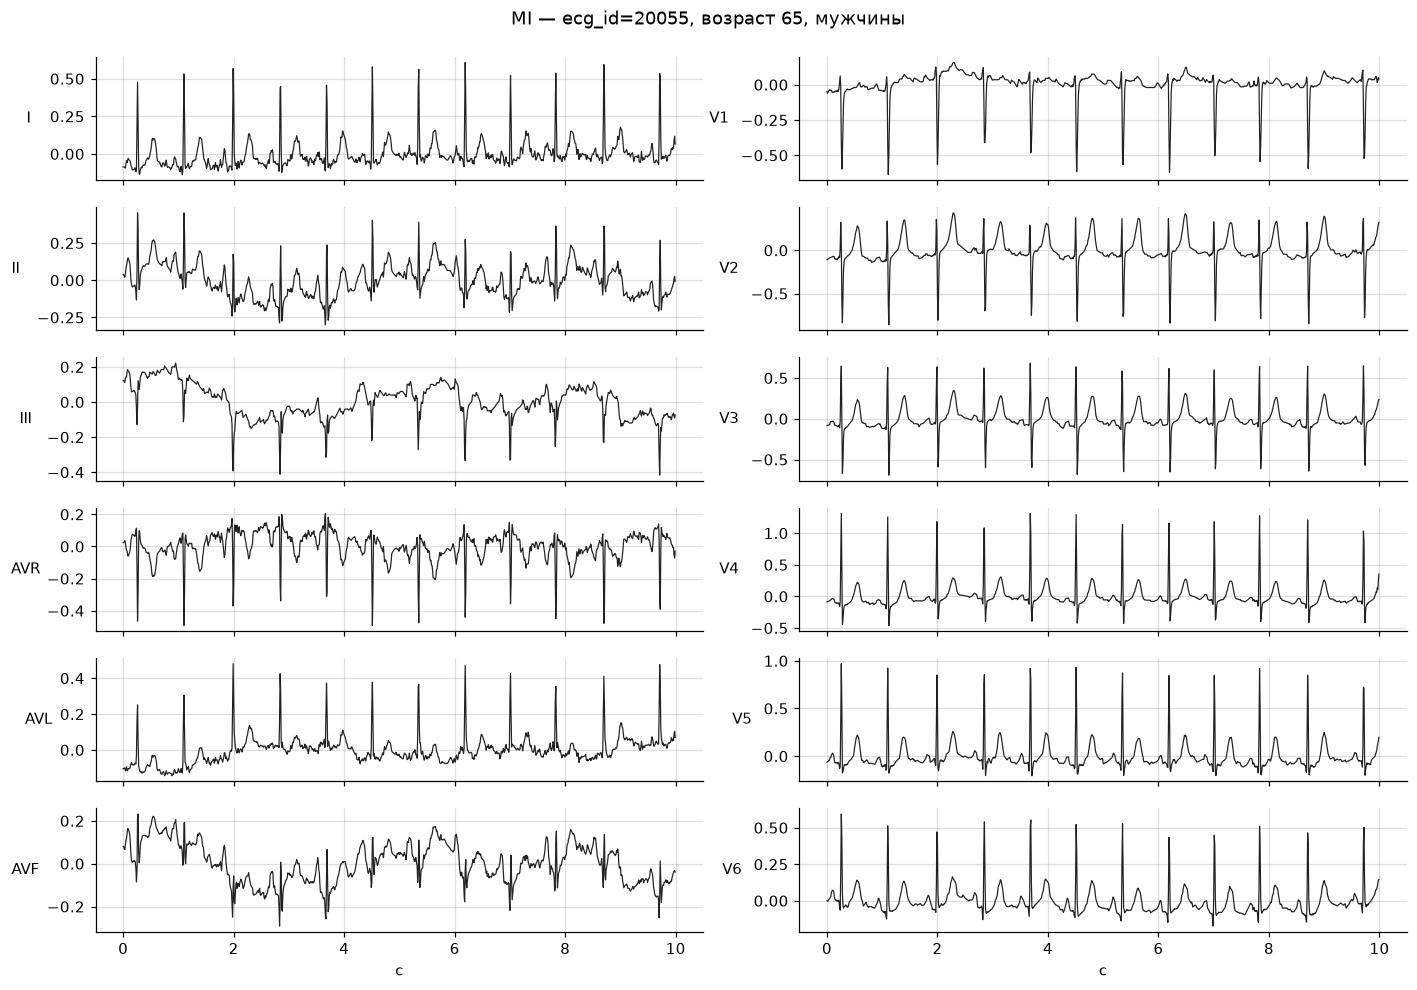

In [7]:
plot_ecg(examples["MI"], f"MI — ecg_id={ecg_id[examples['MI']]}, "
         f"возраст {meta_df['age'].iloc[examples['MI']]:.0f}, {meta_df['sex'].iloc[examples['MI']]}")

**Вывод.** Этот пример скорее показывает сложность задачи, чем хрестоматийный инфаркт: сильный дрейф изолинии и мышечный шум в II, III, aVF, aVR и разная форма комплексов по отведениям; изменения сегмента ST/зубца Q на глаз однозначно не определить. Метка MI в PTB-XL — результат экспертной разметки по многим отведениям, поэтому признак может быть локальным и тонким. Для модели это значит, что помехи и дрейф могут мешать, а предобработка (например, фильтрация изолинии) — гипотеза, которую стоит проверять на val, а не принимать на веру.

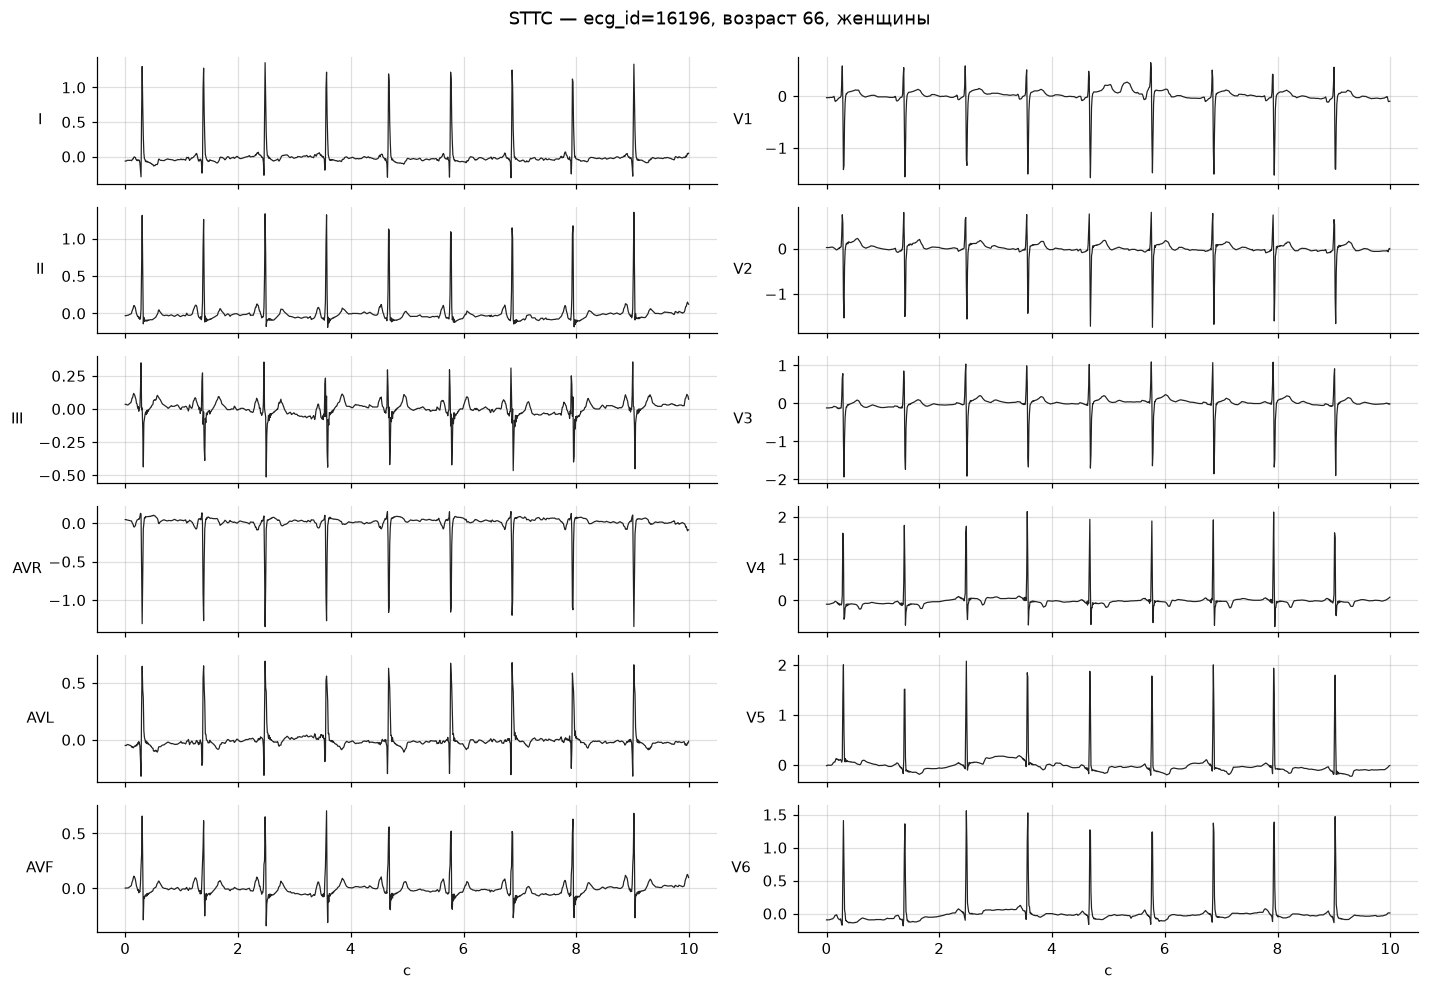

In [8]:
plot_ecg(examples["STTC"], f"STTC — ecg_id={ecg_id[examples['STTC']]}, "
         f"возраст {meta_df['age'].iloc[examples['STTC']]:.0f}, {meta_df['sex'].iloc[examples['STTC']]}")

**Вывод.** Ритм регулярный (≈55 уд/мин), QRS узкий и высокоамплитудный (R до ≈2 мВ в V4–V5, глубокий S до ≈−1.7 мВ в V1–V3). Зубцы T в I и II плоские/низкоамплитудные, в V4 заметны отрицательные T — это согласуется с классом нарушений ST/T, но на одном примере я не делаю клинических выводов. Различия с нормой здесь тонкие и сосредоточены в форме сегмента ST и зубца T, а не в крупной морфологии QRS.

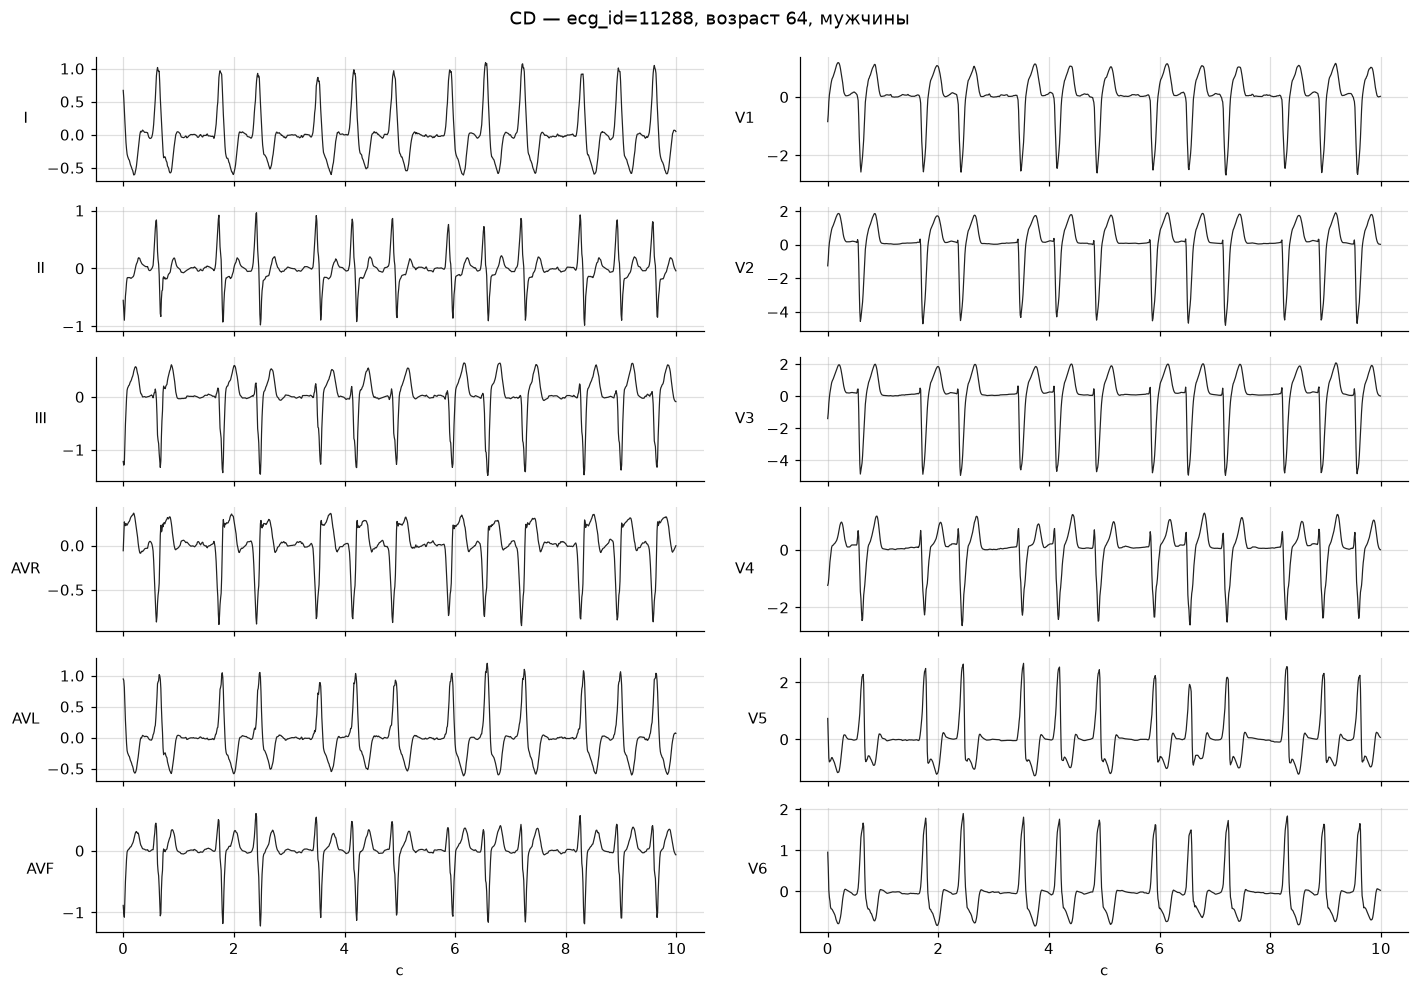

In [9]:
plot_ecg(examples["CD"], f"CD — ecg_id={ecg_id[examples['CD']]}, "
         f"возраст {meta_df['age'].iloc[examples['CD']]:.0f}, {meta_df['sex'].iloc[examples['CD']]}")

**Вывод.** Здесь различие видно сразу: комплексы QRS заметно широкие и деформированные, в V1–V3 глубокие S-зубцы (до ≈−5 мВ) с широкими дискордантными T, амплитуды в целом больше, чем в других примерах; ритм слегка неравномерный. Такой вид характерен для нарушений проводимости (блокад ножек пучка Гиса), но это только визуальное впечатление по одному примеру. CD — наиболее «морфологически очевидный» класс, поэтому ожидаем у него один из самых высоких AUROC.

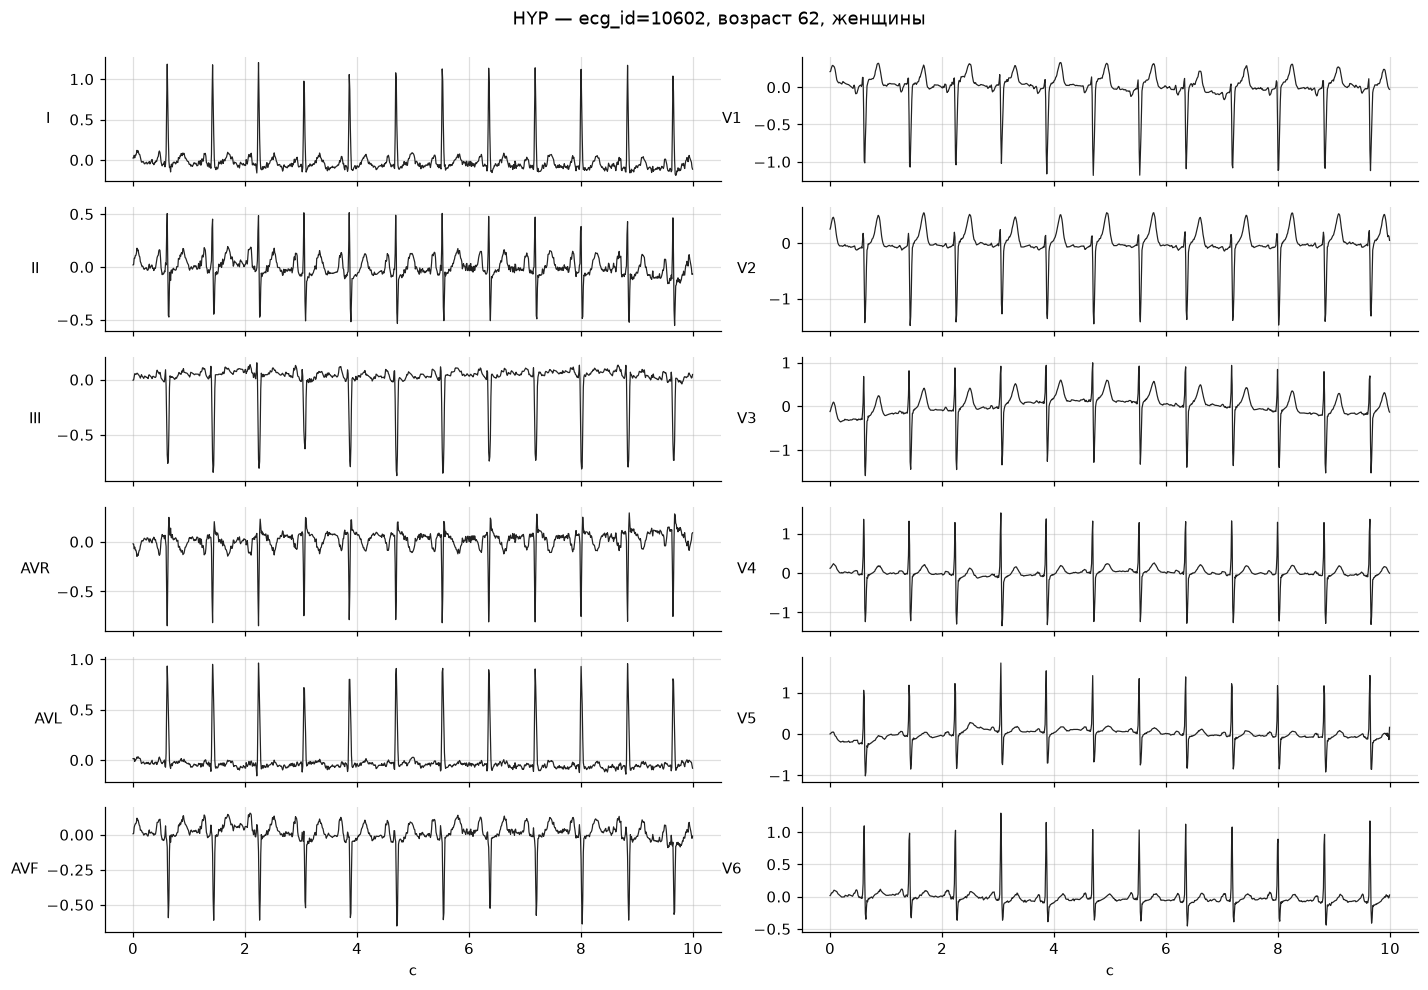

In [10]:
plot_ecg(examples["HYP"], f"HYP — ecg_id={ecg_id[examples['HYP']]}, "
         f"возраст {meta_df['age'].iloc[examples['HYP']]:.0f}, {meta_df['sex'].iloc[examples['HYP']]}")

**Вывод.** Ритм регулярный (≈75 уд/мин), QRS узкий; в V1–V3 глубокие S-зубцы (≈−1.5 мВ), в I и aVL высокие R (≈1 мВ) — амплитудные признаки гипертрофии заметны умеренно, а остальные детали на глаз тонкие. Гипертрофия определяется по соотношению амплитуд между отведениями, поэтому важно сохранять сырой масштаб по отведениям; per-lead нормализация по train это допускает (статистики общие для всех записей, а не по записи), нормализация каждой записи по отдельности амплитудные соотношения бы исказила.

## Итоговые выводы для моделирования

**Вывод.** 1. **Метрики.** Основная — macro AUROC (устойчива к дисбалансу), но смотреть и AUROC по классам: HYP самый редкий (12.5%), NORM самый частый (44.5%). Пороги для F1 подбираем по val.
2. **Лосс и выход.** Sigmoid + BCE с `pos_weight` по train, а не softmax: 24% записей имеют несколько меток.
3. **Разбиение.** Доли классов в train и val совпадают, так что val репрезентативен; тестовый фолд 10 в этом анализе не использовался.
4. **Смещения.** Возраст и пол связаны с классом (NORM моложе на ~12 лет, среди MI/CD мало женщин) — проверить качество в подгруппах и не выдавать результат за клинически применимый.
5. **Возраст 300.** Значения ≥120 — кодировка >89 лет, при использовании возраста как признака обрабатывать отдельно (здесь исключены из статистики).
6. **Сигнал.** Дрейф изолинии и шум видны уже на примерах (особенно MI); предобработку и аугментации проверять экспериментами на val.
7. **Метки.** Возможен шум меток (NORM+CD у 4% NORM-записей); пока оставляем как есть в соответствии с протоколом PTB-XL.